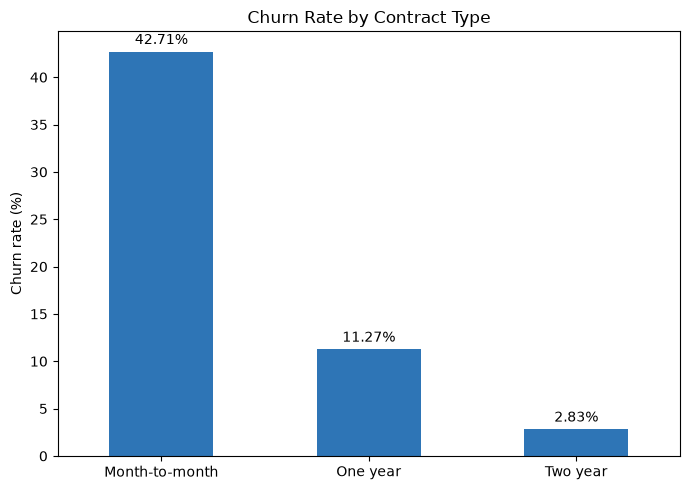

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned/telco_churn_cleaned.csv")

rate = (
    df.assign(churned=(df["Churn"] == "Yes"))
      .groupby("Contract")["churned"].mean()
      .mul(100).round(2)
      .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
ax = rate.plot(kind="bar", color="#2E75B6")
ax.set_title("Churn Rate by Contract Type")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
for i, v in enumerate(rate):
    ax.text(i, v + 0.8, f"{v}%", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

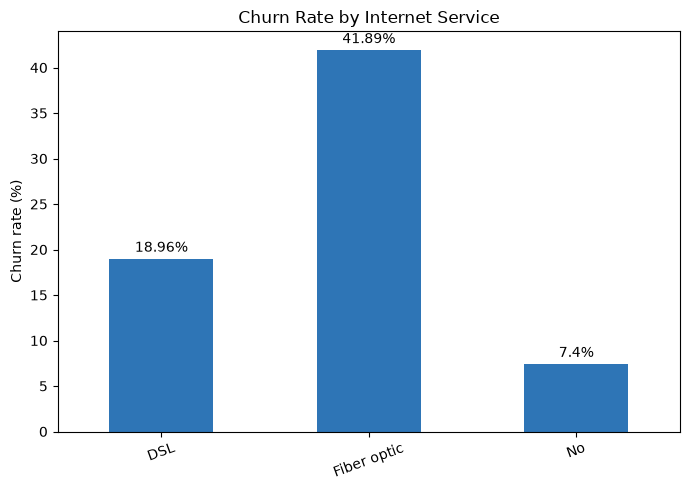

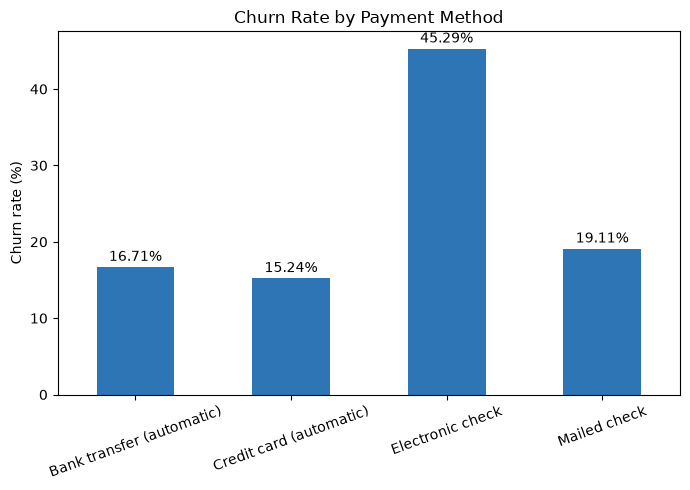

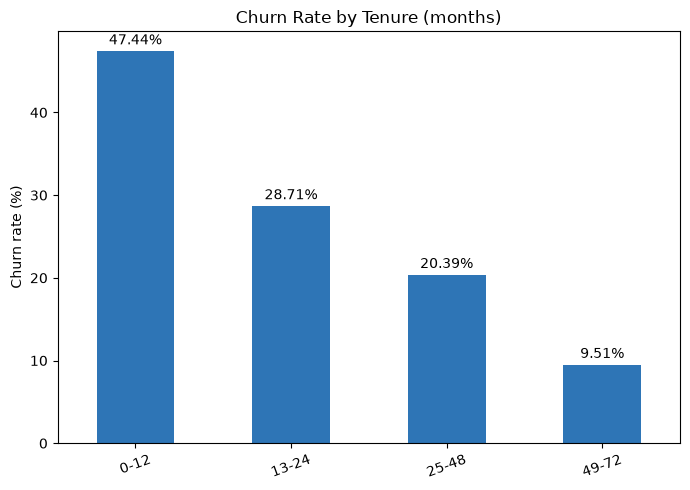

In [2]:
df["churned"] = (df["Churn"] == "Yes")

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)

def churn_chart(column, title):
    rate = df.groupby(column, observed=True)["churned"].mean().mul(100).round(2)
    plt.figure(figsize=(7, 5))
    ax = rate.plot(kind="bar", color="#2E75B6")
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    for i, v in enumerate(rate):
        ax.text(i, v + 0.8, f"{v}%", ha="center")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

churn_chart("InternetService", "Churn Rate by Internet Service")
churn_chart("PaymentMethod", "Churn Rate by Payment Method")
churn_chart("tenure_group", "Churn Rate by Tenure (months)")

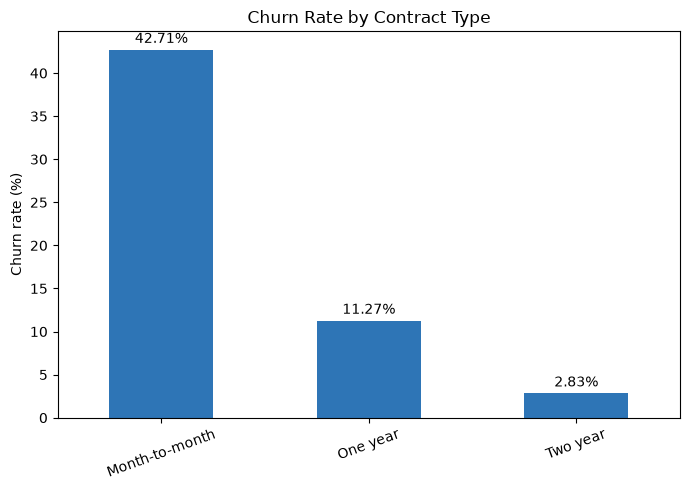

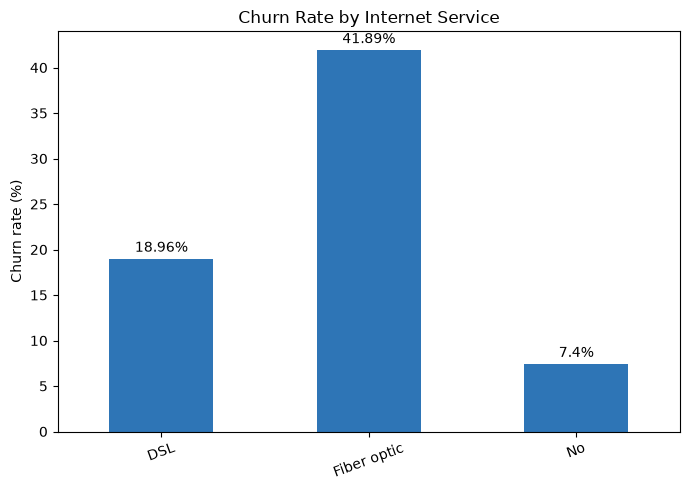

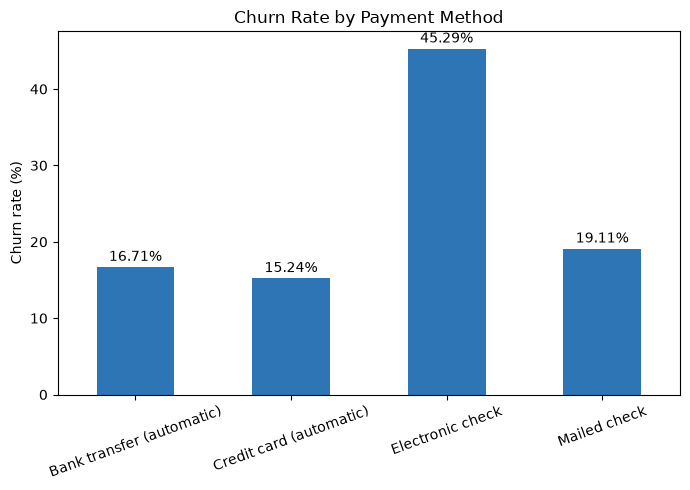

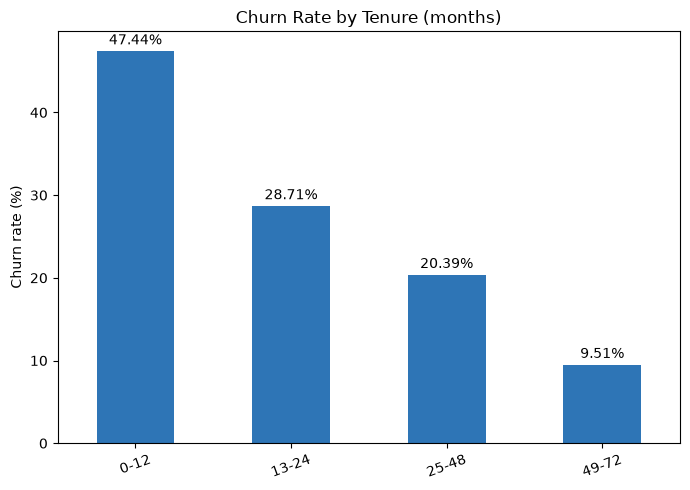

In [3]:
import os
os.makedirs("../docs/charts", exist_ok=True)

def churn_chart(column, title, filename):
    rate = df.groupby(column, observed=True)["churned"].mean().mul(100).round(2)
    plt.figure(figsize=(7, 5))
    ax = rate.plot(kind="bar", color="#2E75B6")
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    for i, v in enumerate(rate):
        ax.text(i, v + 0.8, f"{v}%", ha="center")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(f"../docs/charts/{filename}", dpi=150)
    plt.show()

churn_chart("Contract", "Churn Rate by Contract Type", "churn_by_contract.png")
churn_chart("InternetService", "Churn Rate by Internet Service", "churn_by_internet.png")
churn_chart("PaymentMethod", "Churn Rate by Payment Method", "churn_by_payment.png")
churn_chart("tenure_group", "Churn Rate by Tenure (months)", "churn_by_tenure.png")